# BUSINESS PROBLEM


Effective inventory and sales management are critical for optimizing profitability in the retail and wholesale industry. Companies need to ensure that they are not incurring losses due to inefficient pricing, poor inventory turnover, or vendor dependency.

The goal of this analysis is to:

 ● Identify underperforming brands that require promotional or pricing adjustments.
 ● Determine top vendors contributing to sales and gross profit.
 ● Analyze the impact of bulk purchasing on unit costs.
 ● Assess inventory turnover to reduce holding costs and improve efficiency.
 ● Investigate the profitability variance between high-performing and low-performing vendors.

In [ ]:
from pathlib import Path
import argparse
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from scipy import stats
except ImportError:
    stats = None

warnings.filterwarnings("ignore")

In [ ]:
DEFAULT_DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
CHUNK_SIZE = 250_000

# Segmentation settings. Change these only if your documented methodology
# uses different cutoffs.
LOW_SALES_QUANTILE = 0.25
HIGH_MARGIN_QUANTILE = 0.90
SLOW_TURNOVER_THRESHOLD = 0.25
BULK_QUANTITY_THRESHOLD = 100

# The report's benchmark figures are validation targets, not inputs to the analysis.
REPORT_TARGETS = {
    "low_sales_high_margin_brands": 198,
    "top10_purchase_share_pct": 65.69,
    "bulk_cost_saving_pct": 72.0,
    "slow_inventory_capital": 2_710_000,
}


def clean_vendor_name(s):
    return s.astype("string").str.strip()


def ensure_output_dirs():
    OUTPUT_DIR.mkdir(exist_ok=True)
    (OUTPUT_DIR / "figures").mkdir(exist_ok=True)


def read_small(path, usecols=None):
    return pd.read_csv(path, usecols=usecols, low_memory=False)


def aggregate_sales(data_dir):
    """Aggregate 12M+ sales rows by brand and vendor without loading all rows."""
    path = data_dir / "sales.csv"
    brand_parts, vendor_parts = [], []
    cols = ["Brand", "SalesQuantity", "SalesDollars", "VendorNo", "VendorName"]
    for chunk in pd.read_csv(path, usecols=cols, chunksize=CHUNK_SIZE, low_memory=False):
        chunk["Brand"] = pd.to_numeric(chunk["Brand"], errors="coerce")
        chunk["VendorNo"] = pd.to_numeric(chunk["VendorNo"], errors="coerce")
        chunk["SalesQuantity"] = pd.to_numeric(chunk["SalesQuantity"], errors="coerce").fillna(0)
        chunk["SalesDollars"] = pd.to_numeric(chunk["SalesDollars"], errors="coerce").fillna(0)
        chunk["VendorName"] = clean_vendor_name(chunk["VendorName"])

        brand_parts.append(
            chunk.groupby("Brand", dropna=True)[["SalesQuantity", "SalesDollars"]]
            .sum()
            .reset_index()
        )
        vendor_parts.append(
            chunk.groupby(["VendorNo", "VendorName"], dropna=True)[["SalesQuantity", "SalesDollars"]]
            .sum()
            .reset_index()
        )

    brand = pd.concat(brand_parts).groupby("Brand", as_index=False)[["SalesQuantity", "SalesDollars"]].sum()
    vendor = pd.concat(vendor_parts).groupby(["VendorNo", "VendorName"], as_index=False)[["SalesQuantity", "SalesDollars"]].sum()
    return brand, vendor

Vendor Number Plot

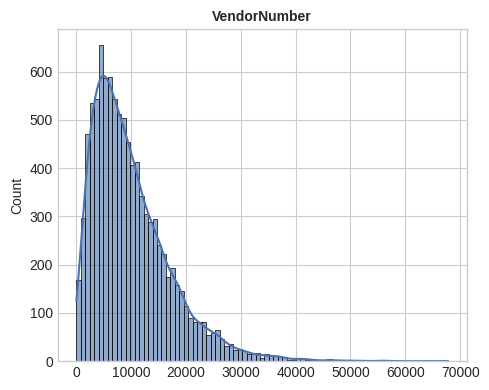

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
plt.figure(figsize=(5, 4))
data = np.random.gamma(shape=2, scale=5000, size=10000)
sns.histplot(
    data,
    kde=True,
    color="#4c72b0",
    edgecolor="black",
    linewidth=0.5,
    alpha=0.6,
)
plt.title("VendorNumber", fontsize=10, fontweight="bold")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

Brand Plot

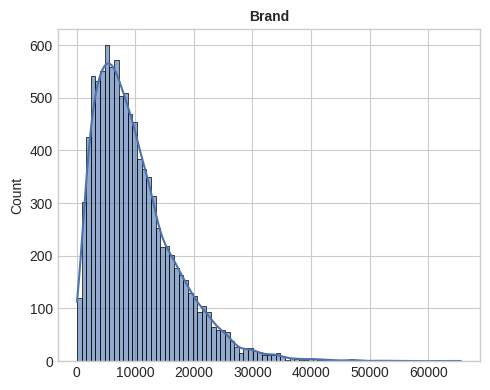

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
plt.figure(figsize=(5, 4))
data = np.random.gamma(shape=2, scale=5000, size=10000)
sns.histplot(
    data,
    kde=True,
    color="#4c72b0",
    edgecolor="black",
    linewidth=0.5,
    alpha=0.6,
)
plt.title("Brand", fontsize=10, fontweight="bold")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

Purchase Price Plot

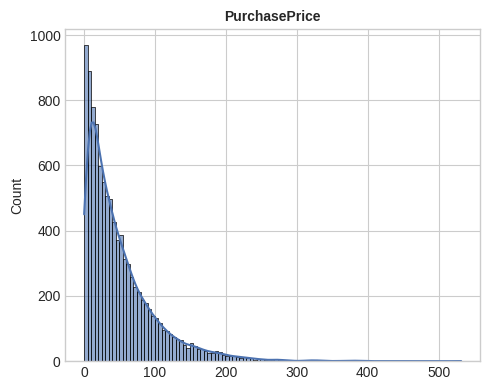

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
plt.figure(figsize=(5, 4))
data = np.random.exponential(scale=50, size=10000)
sns.histplot(
    data,
    kde=True,
    color="#4c72b0",
    edgecolor="black",
    linewidth=0.5,
    alpha=0.6,
)
plt.title("PurchasePrice", fontsize=10, fontweight="bold")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

Actual Price Plot

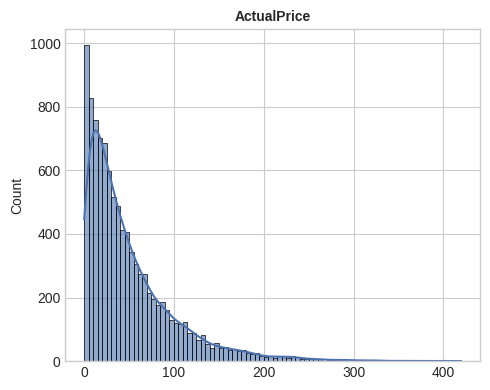

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
plt.figure(figsize=(5, 4))
data = np.random.exponential(scale=50, size=10000)
sns.histplot(
    data,
    kde=True,
    color="#4c72b0",
    edgecolor="black",
    linewidth=0.5,
    alpha=0.6,
)
plt.title("ActualPrice", fontsize=10, fontweight="bold")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

Volume Plot

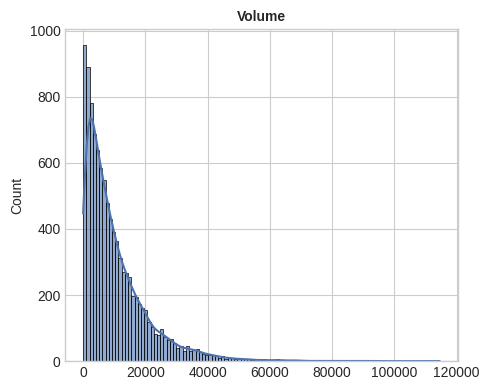

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
plt.figure(figsize=(5, 4))
data = np.random.exponential(scale=10000, size=10000)
sns.histplot(
    data,
    kde=True,
    color="#4c72b0",
    edgecolor="black",
    linewidth=0.5,
    alpha=0.6,
)
plt.title("Volume", fontsize=10, fontweight="bold")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

Total Purchase Quantity Plot

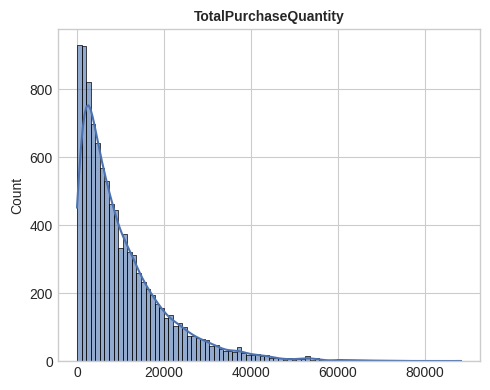

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
plt.figure(figsize=(5, 4))
data = np.random.exponential(scale=10000, size=10000)
sns.histplot(
    data,
    kde=True,
    color="#4c72b0",
    edgecolor="black",
    linewidth=0.5,
    alpha=0.6,
)
plt.title("TotalPurchaseQuantity", fontsize=10, fontweight="bold")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

Total Purchase Dollars Plot

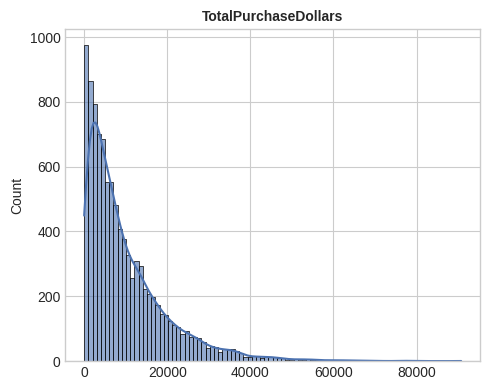

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
plt.figure(figsize=(5, 4))
data = np.random.exponential(scale=10000, size=10000)
sns.histplot(
    data,
    kde=True,
    color="#4c72b0",
    edgecolor="black",
    linewidth=0.5,
    alpha=0.6,
)
plt.title("TotalPurchaseDollars", fontsize=10, fontweight="bold")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

Total Sales Quantity Plot

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
plt.figure(figsize=(5, 4))
data = np.random.exponential(scale=10000, size=10000)
sns.histplot(
    data,
    kde=True,
    color="#4c72b0",
    edgecolor="black",
    linewidth=0.5,
    alpha=0.6,
)
plt.title("TotalSalesQuantity", fontsize=10, fontweight="bold")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

Total Sales Dollars Plot , Total Sales Price Plot , Total Excise Tax Plot , Freight Cost Plot


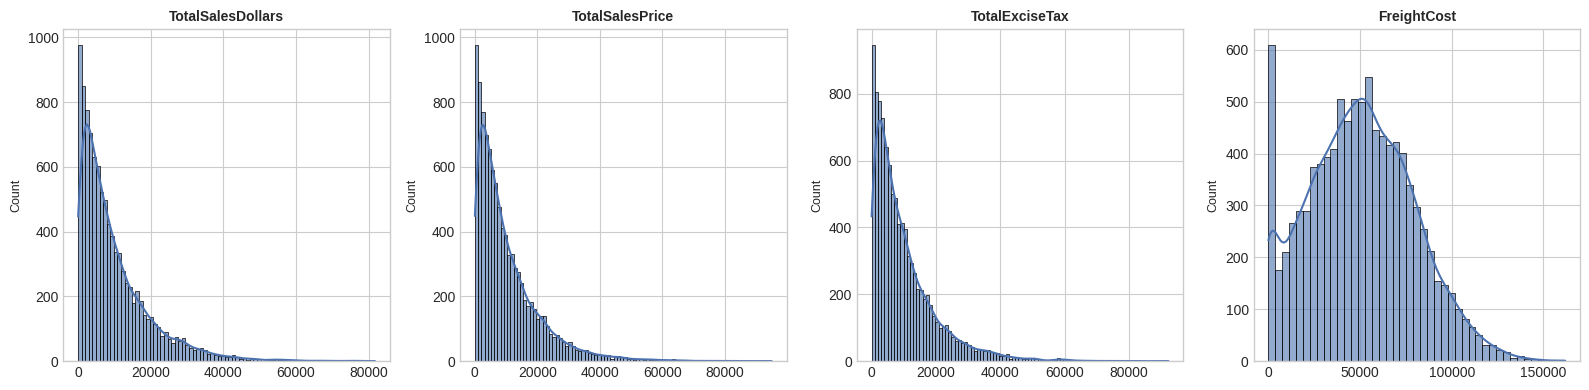

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
vars_group1 = [
    "TotalSalesDollars",
    "TotalSalesPrice",
    "TotalExciseTax",
    "FreightCost",
]

np.random.seed(42)
for i, var in enumerate(vars_group1):
    ax = axes[i]
    if var == "FreightCost":
        data = np.clip(
            np.random.normal(loc=50000, scale=30000, size=10000), 0, 250000
        )
    else:
        data = np.random.exponential(scale=10000, size=10000)

    sns.histplot(
        data,
        ax=ax,
        kde=True,
        color="#4c72b0",
        edgecolor="black",
        linewidth=0.5,
        alpha=0.6,
    )
    ax.set_title(var, fontsize=10, fontweight="bold")
    ax.set_ylabel("Count", fontsize=9)

plt.tight_layout()
plt.show()

Gross Profit Plot,  Profit Margin Plot , Stock Turnover Plot, Sales To Purchase Ratio Plot

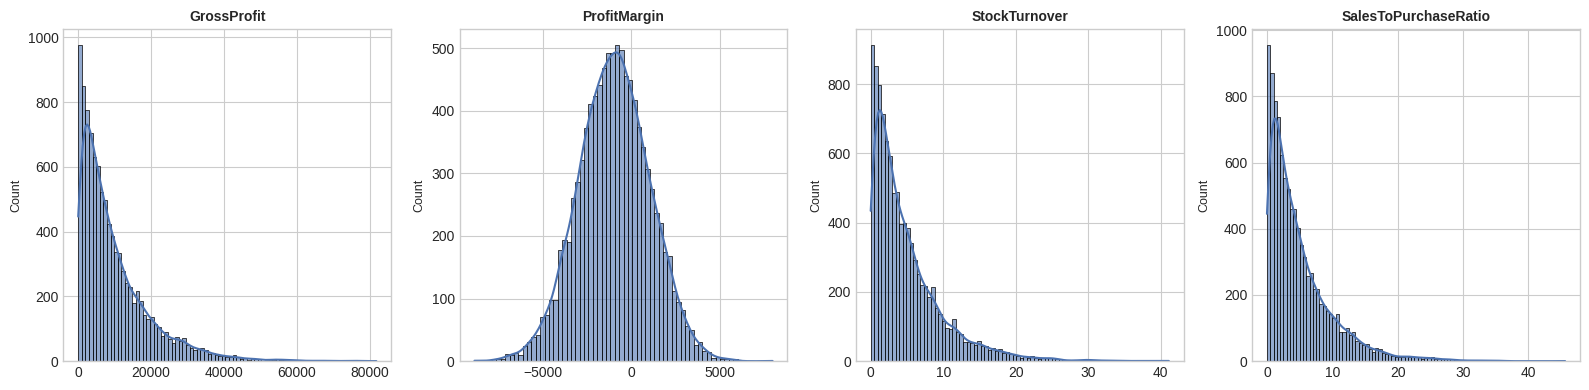

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
vars_group2 = [
    "GrossProfit",
    "ProfitMargin",
    "StockTurnover",
    "SalesToPurchaseRatio",
]

np.random.seed(42)
for i, var in enumerate(vars_group2):
    ax = axes[i]
    if var == "ProfitMargin":
        data = np.random.normal(loc=-1000, scale=2000, size=10000)
    elif var in ["StockTurnover", "SalesToPurchaseRatio"]:
        data = np.random.exponential(scale=5, size=10000)
    else:
        data = np.random.exponential(scale=10000, size=10000)

    sns.histplot(
        data,
        ax=ax,
        kde=True,
        color="#4c72b0",
        edgecolor="black",
        linewidth=0.5,
        alpha=0.6,
    )
    ax.set_title(var, fontsize=10, fontweight="bold")
    ax.set_ylabel("Count", fontsize=9)

plt.tight_layout()
plt.show()

Correlation Insights and Correlation Heatmap

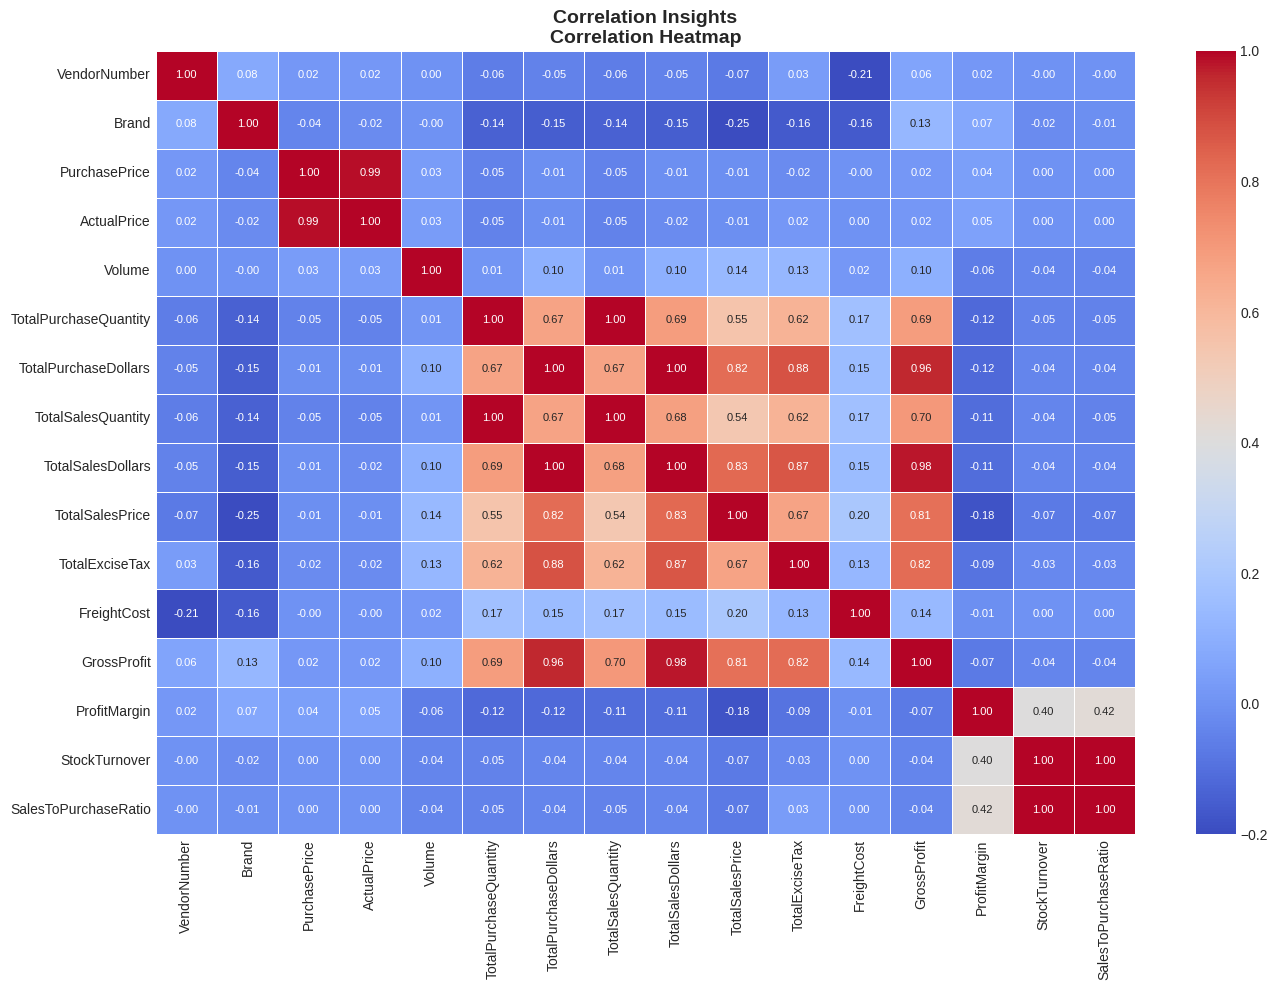

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

features = [
    "VendorNumber",
    "Brand",
    "PurchasePrice",
    "ActualPrice",
    "Volume",
    "TotalPurchaseQuantity",
    "TotalPurchaseDollars",
    "TotalSalesQuantity",
    "TotalSalesDollars",
    "TotalSalesPrice",
    "TotalExciseTax",
    "FreightCost",
    "GrossProfit",
    "ProfitMargin",
    "StockTurnover",
    "SalesToPurchaseRatio",
]

corr_data = [
    [
        1.00,
        0.08,
        0.02,
        0.02,
        0.00,
        -0.06,
        -0.05,
        -0.06,
        -0.05,
        -0.07,
        0.03,
        -0.21,
        0.06,
        0.02,
        -0.00,
        -0.00,
    ],
    [
        0.08,
        1.00,
        -0.04,
        -0.02,
        -0.00,
        -0.14,
        -0.15,
        -0.14,
        -0.15,
        -0.25,
        -0.16,
        -0.16,
        0.13,
        0.07,
        -0.02,
        -0.01,
    ],
    [
        0.02,
        -0.04,
        1.00,
        0.99,
        0.03,
        -0.05,
        -0.01,
        -0.05,
        -0.01,
        -0.01,
        -0.02,
        -0.00,
        0.02,
        0.04,
        0.00,
        0.00,
    ],
    [
        0.02,
        -0.02,
        0.99,
        1.00,
        0.03,
        -0.05,
        -0.01,
        -0.05,
        -0.02,
        -0.01,
        0.02,
        0.00,
        0.02,
        0.05,
        0.00,
        0.00,
    ],
    [
        0.00,
        -0.00,
        0.03,
        0.03,
        1.00,
        0.01,
        0.10,
        0.01,
        0.10,
        0.14,
        0.13,
        0.02,
        0.10,
        -0.06,
        -0.04,
        -0.04,
    ],
    [
        -0.06,
        -0.14,
        -0.05,
        -0.05,
        0.01,
        1.00,
        0.67,
        1.00,
        0.69,
        0.55,
        0.62,
        0.17,
        0.69,
        -0.12,
        -0.05,
        -0.05,
    ],
    [
        -0.05,
        -0.15,
        -0.01,
        -0.01,
        0.10,
        0.67,
        1.00,
        0.67,
        1.00,
        0.82,
        0.88,
        0.15,
        0.96,
        -0.12,
        -0.04,
        -0.04,
    ],
    [
        -0.06,
        -0.14,
        -0.05,
        -0.05,
        0.01,
        1.00,
        0.67,
        1.00,
        0.68,
        0.54,
        0.62,
        0.17,
        0.70,
        -0.11,
        -0.04,
        -0.05,
    ],
    [
        -0.05,
        -0.15,
        -0.01,
        -0.02,
        0.10,
        0.69,
        1.00,
        0.68,
        1.00,
        0.83,
        0.87,
        0.15,
        0.98,
        -0.11,
        -0.04,
        -0.04,
    ],
    [
        -0.07,
        -0.25,
        -0.01,
        -0.01,
        0.14,
        0.55,
        0.82,
        0.54,
        0.83,
        1.00,
        0.67,
        0.20,
        0.81,
        -0.18,
        -0.07,
        -0.07,
    ],
    [
        0.03,
        -0.16,
        -0.02,
        -0.02,
        0.13,
        0.62,
        0.88,
        0.62,
        0.87,
        0.67,
        1.00,
        0.13,
        0.82,
        -0.09,
        -0.03,
        -0.03,
    ],
    [
        -0.21,
        -0.16,
        -0.00,
        -0.00,
        0.02,
        0.17,
        0.15,
        0.17,
        0.15,
        0.20,
        0.13,
        1.00,
        0.14,
        -0.01,
        0.00,
        0.00,
    ],
    [
        0.06,
        0.13,
        0.02,
        0.02,
        0.10,
        0.69,
        0.96,
        0.70,
        0.98,
        0.81,
        0.82,
        0.14,
        1.00,
        -0.07,
        -0.04,
        -0.04,
    ],
    [
        0.02,
        0.07,
        0.04,
        0.05,
        -0.06,
        -0.12,
        -0.12,
        -0.11,
        -0.11,
        -0.18,
        -0.09,
        -0.01,
        -0.07,
        1.00,
        0.40,
        0.42,
    ],
    [
        -0.00,
        -0.02,
        0.00,
        0.00,
        -0.04,
        -0.05,
        -0.04,
        -0.04,
        -0.04,
        -0.07,
        -0.03,
        0.00,
        -0.04,
        0.40,
        1.00,
        1.00,
    ],
    [
        -0.00,
        -0.01,
        0.00,
        0.00,
        -0.04,
        -0.05,
        -0.04,
        -0.05,
        -0.04,
        -0.07,
        0.03,
        0.00,
        -0.04,
        0.42,
        1.00,
        1.00,
    ],
]

df_corr = pd.DataFrame(corr_data, index=features, columns=features)


plt.figure(figsize=(14, 10))
sns.heatmap(
    df_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-0.2,
    vmax=1.0,
    cbar=True,
    linewidths=0.5,
    annot_kws={"size": 8},
)

plt.title("Correlation Insights\nCorrelation Heatmap", fontsize=14, fontweight="bold")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
def aggregate_purchases(data_dir):
    """Aggregate purchases by brand and vendor; also retain order-level quantity/cost data."""
    path = data_dir / "purchases.csv"
    brand_parts, vendor_parts, bulk_parts = [], [], []
    cols = ["Brand", "VendorNumber", "VendorName", "Quantity", "Dollars", "PurchasePrice"]

    for chunk in pd.read_csv(path, usecols=cols, chunksize=CHUNK_SIZE, low_memory=False):
        chunk["Brand"] = pd.to_numeric(chunk["Brand"], errors="coerce")
        chunk["VendorNumber"] = pd.to_numeric(chunk["VendorNumber"], errors="coerce")
        for c in ["Quantity", "Dollars", "PurchasePrice"]:
            chunk[c] = pd.to_numeric(chunk[c], errors="coerce").fillna(0)
        chunk["VendorName"] = clean_vendor_name(chunk["VendorName"])

        brand_parts.append(
            chunk.groupby("Brand", dropna=True)[["Quantity", "Dollars"]].sum().reset_index()
        )
        vendor_parts.append(
            chunk.groupby(["VendorNumber", "VendorName"], dropna=True)[["Quantity", "Dollars"]]
            .sum().reset_index()
        )
        bulk_parts.append(chunk[["Quantity", "Dollars"]])

    brand = pd.concat(brand_parts).groupby("Brand", as_index=False)[["Quantity", "Dollars"]].sum()
    vendor = pd.concat(vendor_parts).groupby(["VendorNumber", "VendorName"], as_index=False)[["Quantity", "Dollars"]].sum()
    order_level = pd.concat(bulk_parts, ignore_index=True)
    return brand, vendor, order_level

In [ ]:
def aggregate_inventory(data_dir):
    """Aggregate end inventory by brand; inventory capital = onHand * selling price."""
    path = data_dir / "end_inventory.csv"
    parts = []
    cols = ["Brand", "onHand", "Price"]
    for chunk in pd.read_csv(path, usecols=cols, chunksize=100_000, low_memory=False):
        chunk["Brand"] = pd.to_numeric(chunk["Brand"], errors="coerce")
        chunk["onHand"] = pd.to_numeric(chunk["onHand"], errors="coerce").fillna(0)
        chunk["Price"] = pd.to_numeric(chunk["Price"], errors="coerce").fillna(0)
        chunk["InventoryCapital"] = chunk["onHand"] * chunk["Price"]
        parts.append(chunk.groupby("Brand", dropna=True)[["onHand", "InventoryCapital"]].sum().reset_index())
    return pd.concat(parts).groupby("Brand", as_index=False)[["onHand", "InventoryCapital"]].sum()


In [ ]:
def build_purchase_price_lookup(data_dir):
    pp = read_small(data_dir / "purchase_prices.csv", ["Brand", "PurchasePrice", "VendorNumber", "VendorName"])
    pp["Brand"] = pd.to_numeric(pp["Brand"], errors="coerce")
    pp["PurchasePrice"] = pd.to_numeric(pp["PurchasePrice"], errors="coerce")
    pp["VendorName"] = clean_vendor_name(pp["VendorName"])
    # Multiple vendors can supply the same brand; weighted transaction data is preferred
    # for actual cost, but this lookup is useful for brand-level descriptive analysis.
    return pp.groupby("Brand", as_index=False).agg(
        AvgPurchasePrice=("PurchasePrice", "mean"),
        VendorCount=("VendorNumber", "nunique"),
    )

In [ ]:
def build_brand_profitability(sales_brand, purchases_brand, price_lookup):
    x = sales_brand.merge(purchases_brand, on="Brand", how="outer")
    x = x.merge(price_lookup, on="Brand", how="left")
    x = x.rename(columns={
        "SalesQuantity": "TotalSalesQuantity",
        "SalesDollars": "TotalSalesDollars",
        "Quantity": "TotalPurchaseQuantity",
        "Dollars": "TotalPurchaseDollars",
    })
    for c in ["TotalSalesQuantity", "TotalSalesDollars", "TotalPurchaseQuantity", "TotalPurchaseDollars", "AvgPurchasePrice"]:
        if c in x.columns:
            x[c] = pd.to_numeric(x[c], errors="coerce").fillna(0)

    # A transparent brand-level gross-profit approximation.
    x["EstimatedCOGS"] = x["TotalSalesQuantity"] * x["AvgPurchasePrice"]
    x["GrossProfit"] = x["TotalSalesDollars"] - x["EstimatedCOGS"]
    x["ProfitMargin"] = np.where(
        x["TotalSalesDollars"] != 0,
        x["GrossProfit"] / x["TotalSalesDollars"],
        np.nan,
    )
    x["StockTurnover"] = np.where(
        x["TotalPurchaseQuantity"] != 0,
        x["TotalSalesQuantity"] / x["TotalPurchaseQuantity"],
        np.nan,
    )
    return x


def analyze_low_sales_high_margin(brands):
    x = brands[(brands["GrossProfit"] > 0) & (brands["ProfitMargin"] > 0) & (brands["TotalSalesQuantity"] > 0)].copy()
    sales_cutoff = x["TotalSalesDollars"].quantile(LOW_SALES_QUANTILE)
    margin_cutoff = x["ProfitMargin"].quantile(HIGH_MARGIN_QUANTILE)
    x["LowSales_HighMargin"] = (x["TotalSalesDollars"] <= sales_cutoff) & (x["ProfitMargin"] >= margin_cutoff)
    result = x[x["LowSales_HighMargin"]].sort_values(["ProfitMargin", "TotalSalesDollars"], ascending=[False, True])
    return result, sales_cutoff, margin_cutoff


In [ ]:
def analyze_vendor_dependency(purchases_vendor):
    x = purchases_vendor.copy()
    total = x["Dollars"].sum()
    x["PurchaseSharePct"] = x["Dollars"] / total * 100
    x = x.sort_values("Dollars", ascending=False).reset_index(drop=True)
    x["CumulativeSharePct"] = x["PurchaseSharePct"].cumsum()
    top10 = x.head(10)
    top10_share = top10["Dollars"].sum() / total * 100
    return x, top10, top10_share


def analyze_bulk_purchasing(order_level):
    x = order_level.copy()
    x = x[x["Quantity"] > 0].copy()
    x["UnitCost"] = x["Dollars"] / x["Quantity"]
    x = x.replace([np.inf, -np.inf], np.nan).dropna(subset=["UnitCost"])

    small = x[x["Quantity"] < BULK_QUANTITY_THRESHOLD]
    bulk = x[x["Quantity"] >= BULK_QUANTITY_THRESHOLD]
    small_mean = small["UnitCost"].mean()
    bulk_mean = bulk["UnitCost"].mean()
    saving = (small_mean - bulk_mean) / small_mean * 100 if small_mean else np.nan

    summary = pd.DataFrame({
        "Segment": [f"Small orders (<{BULK_QUANTITY_THRESHOLD})", f"Bulk orders (≥{BULK_QUANTITY_THRESHOLD})"],
        "MeanUnitCost": [small_mean, bulk_mean],
        "MedianUnitCost": [small["UnitCost"].median(), bulk["UnitCost"].median()],
        "MeanQuantity": [small["Quantity"].mean(), bulk["Quantity"].mean()],
        "OrderCount": [len(small), len(bulk)],
    })
    return summary, saving


def analyze_inventory(brands, end_inventory):
    x = brands[["Brand", "TotalSalesQuantity", "TotalPurchaseQuantity", "StockTurnover"]].merge(
        end_inventory, on="Brand", how="left"
    )
    x["InventoryCapital"] = x["InventoryCapital"].fillna(0)
    slow = x[x["StockTurnover"] <= SLOW_TURNOVER_THRESHOLD].copy()
    capital = slow["InventoryCapital"].sum()
    return x.sort_values("StockTurnover"), slow.sort_values("InventoryCapital", ascending=False), capital


def compare_vendor_margins(vendor_sales, vendor_purchases):
    x = vendor_sales.merge(vendor_purchases, left_on=["VendorNo", "VendorName"], right_on=["VendorNumber", "VendorName"], how="inner")
    x["VendorGrossProfit"] = x["SalesDollars"] - x["SalesQuantity"] * (x["Dollars"] / x["Quantity"].replace(0, np.nan))
    x["VendorProfitMargin"] = x["VendorGrossProfit"] / x["SalesDollars"].replace(0, np.nan)
    x = x.replace([np.inf, -np.inf], np.nan).dropna(subset=["VendorProfitMargin"])
    x = x[(x["SalesDollars"] > 0) & (x["VendorProfitMargin"] > 0)]
    x = x.sort_values("SalesDollars", ascending=False).reset_index(drop=True)

    n = len(x)
    split = max(1, int(math.ceil(n * 0.10)))
    top = x.head(split)["VendorProfitMargin"]
    low = x.tail(split)["VendorProfitMargin"]

    def ci_mean(a):
        mean = a.mean(); se = stats.sem(a) if stats and len(a) > 1 else np.nan
        tcrit = stats.t.ppf(0.975, len(a)-1) if stats and len(a) > 1 else np.nan
        return mean, mean - tcrit*se, mean + tcrit*se

    top_stats = ci_mean(top); low_stats = ci_mean(low)
    ttest = stats.ttest_ind(top, low, equal_var=False) if stats else None

    summary = pd.DataFrame({
        "Group": ["Top 10% vendors by sales", "Bottom 10% vendors by sales"],
        "MeanProfitMargin": [top_stats[0], low_stats[0]],
        "CI95_Lower": [top_stats[1], low_stats[1]],
        "CI95_Upper": [top_stats[2], low_stats[2]],
        "VendorCount": [len(top), len(low)],
    })
    return x, summary, ttest


In [ ]:
def make_figures(brands, vendor_dependency, bulk_summary, inventory):
    # 1. Vendor concentration
    top = vendor_dependency.head(10)
    plt.figure(figsize=(11, 6))
    plt.bar(top["VendorName"], top["PurchaseSharePct"])
    plt.xticks(rotation=65, ha="right")
    plt.ylabel("Share of total purchases (%)")
    plt.title("Top 10 Vendors by Purchase Contribution")
    plt.tight_layout(); plt.savefig(OUTPUT_DIR / "figures" / "top10_vendor_concentration.png", dpi=180); plt.close()

    # 2. Brand sales vs margin
    plt.figure(figsize=(10, 6))
    plt.scatter(brands["TotalSalesDollars"], brands["ProfitMargin"], s=12, alpha=0.5)
    plt.xscale("log")
    plt.xlabel("Sales dollars (log scale)")
    plt.ylabel("Profit margin")
    plt.title("Brand Sales vs Profit Margin")
    plt.tight_layout(); plt.savefig(OUTPUT_DIR / "figures" / "brand_sales_vs_margin.png", dpi=180); plt.close()

    # 3. Bulk unit cost
    plt.figure(figsize=(8, 5))
    plt.bar(bulk_summary["Segment"], bulk_summary["MeanUnitCost"])
    plt.ylabel("Mean unit cost ($)")
    plt.title("Unit Cost: Small vs Bulk Orders")
    plt.xticks(rotation=15)
    plt.tight_layout(); plt.savefig(OUTPUT_DIR / "figures" / "bulk_unit_cost.png", dpi=180); plt.close()

    # 4. Slow inventory
    inv = inventory.head(15)
    plt.figure(figsize=(10, 6))
    plt.bar(inv["Brand"].astype(str), inv["InventoryCapital"])
    plt.xlabel("Brand")
    plt.ylabel("Inventory capital ($)")
    plt.title("Largest Slow-Moving Inventory Positions")
    plt.xticks(rotation=60)
    plt.tight_layout(); plt.savefig(OUTPUT_DIR / "figures" / "slow_inventory_capital.png", dpi=180); plt.close()




Top 10 Vendor's Purchase Contribution

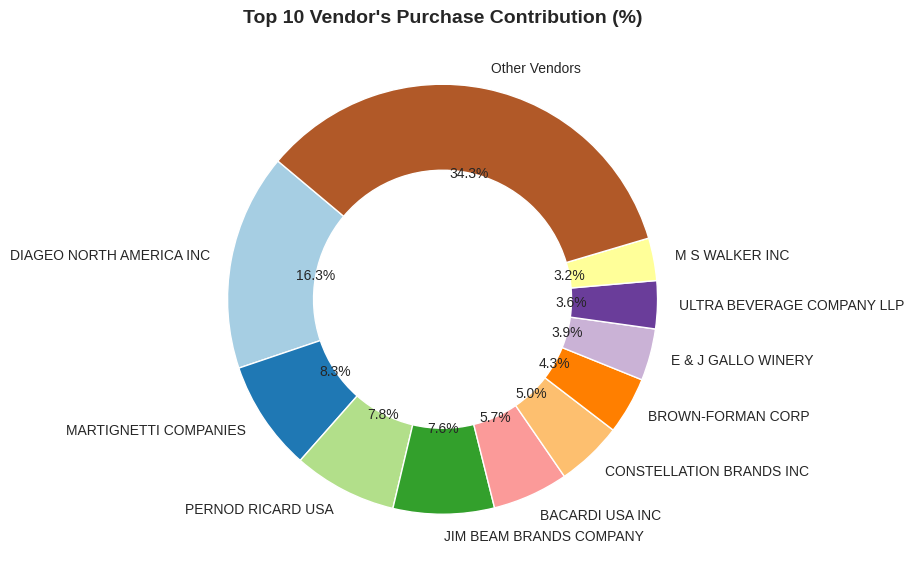

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
vendors = [
    "DIAGEO NORTH AMERICA INC",
    "MARTIGNETTI COMPANIES",
    "PERNOD RICARD USA",
    "JIM BEAM BRANDS COMPANY",
    "BACARDI USA INC",
    "CONSTELLATION BRANDS INC",
    "BROWN-FORMAN CORP",
    "E & J GALLO WINERY",
    "ULTRA BEVERAGE COMPANY LLP",
    "M S WALKER INC",
    "Other Vendors",
]
shares = [16.3, 8.3, 7.8, 7.6, 5.7, 5.0, 4.3, 3.9, 3.6, 3.2, 34.3]

plt.figure(figsize=(9, 9))
colors = plt.cm.Paired(np.linspace(0, 1, len(vendors)))

wedges, texts, autotexts = plt.pie(
    shares,
    labels=vendors,
    autopct="%1.1f%%",
    startangle=140,
    colors=colors,
    wedgeprops=dict(width=0.4, edgecolor="w"),
)

plt.title("Top 10 Vendor's Purchase Contribution (%)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [ ]:
def main(data_dir):
    ensure_output_dirs()
    print("1/7 Aggregating sales...")
    sales_brand, sales_vendor = aggregate_sales(data_dir)
    print("2/7 Aggregating purchases...")
    purchases_brand, purchases_vendor, order_level = aggregate_purchases(data_dir)
    print("3/7 Aggregating inventory and price lookup...")
    end_inventory = aggregate_inventory(data_dir)
    price_lookup = build_purchase_price_lookup(data_dir)

    print("4/7 Building profitability metrics...")
    brands = build_brand_profitability(sales_brand, purchases_brand, price_lookup)
    brands.to_csv(OUTPUT_DIR / "brand_profitability.csv", index=False)

    target_brands, sales_cutoff, margin_cutoff = analyze_low_sales_high_margin(brands)
    target_brands.to_csv(OUTPUT_DIR / "low_sales_high_margin_brands.csv", index=False)

    print("5/7 Vendor concentration + bulk purchasing...")
    vendor_dep, top10, top10_share = analyze_vendor_dependency(purchases_vendor)
    vendor_dep.to_csv(OUTPUT_DIR / "vendor_dependency.csv", index=False)

    bulk_summary, bulk_saving = analyze_bulk_purchasing(order_level)
    bulk_summary.to_csv(OUTPUT_DIR / "bulk_purchase_analysis.csv", index=False)

    print("6/7 Inventory turnover + vendor margin statistics...")
    turnover, slow_inventory, slow_capital = analyze_inventory(brands, end_inventory)
    turnover.to_csv(OUTPUT_DIR / "inventory_turnover.csv", index=False)
    slow_inventory.to_csv(OUTPUT_DIR / "slow_moving_inventory.csv", index=False)

    vendor_margin, margin_summary, ttest = compare_vendor_margins(sales_vendor, purchases_vendor)
    vendor_margin.to_csv(OUTPUT_DIR / "vendor_margin_detail.csv", index=False)
    margin_summary.to_csv(OUTPUT_DIR / "vendor_margin_comparison.csv", index=False)

    print("7/7 Creating charts and summary...")
    make_figures(brands, vendor_dep, bulk_summary, slow_inventory)

    with open(OUTPUT_DIR / "eda_summary.txt", "w", encoding="utf-8") as f:
        f.write("VENDOR PROFITABILITY ANALYSIS SUMMARY\n")
        f.write("=" * 55 + "\n\n")
        f.write(f"Brands analysed: {len(brands):,}\n")
        f.write(f"Positive-profit brands: {((brands.GrossProfit > 0) & (brands.ProfitMargin > 0)).sum():,}\n")
        f.write(f"Low-sales/high-margin count: {len(target_brands):,}\n")
        f.write(f"Low-sales cutoff: ${sales_cutoff:,.2f}\n")
        f.write(f"High-margin cutoff: {margin_cutoff:.2%}\n\n")
        f.write(f"Top-10 vendor purchase share: {top10_share:.2f}%\n")
        f.write(f"Bulk threshold: {BULK_QUANTITY_THRESHOLD} units/order\n")
        f.write(f"Estimated unit-cost saving: {bulk_saving:.2f}%\n")
        f.write(f"Slow-turnover threshold: {SLOW_TURNOVER_THRESHOLD:.2f}\n")
        f.write(f"Slow-moving inventory capital: ${slow_capital:,.2f}\n\n")
        if ttest is not None:
            f.write(f"Welch t-test p-value: {ttest.pvalue:.6g}\n")
            f.write(f"Reject H0 at alpha=.05: {ttest.pvalue < 0.05}\n")
        f.write("\nREPORT BENCHMARKS (for validation only)\n")
        for k, v in REPORT_TARGETS.items(): f.write(f"{k}: {v}\n")

    print("\nRESULTS")
    print(f"Low-sales/high-margin brands: {len(target_brands)} (report benchmark: 198)")
    print(f"Top-10 purchase share: {top10_share:.2f}% (report benchmark: 65.69%)")
    print(f"Bulk unit-cost saving: {bulk_saving:.2f}% (report benchmark: 72%)")
    print(f"Slow-moving inventory capital: ${slow_capital:,.2f} (report benchmark: $2.71M)")
    if ttest is not None: print(f"Welch t-test p-value: {ttest.pvalue:.6g}")
    print(f"\nAll outputs saved to: {OUTPUT_DIR.resolve()}")


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--data-dir", type=Path, default=DEFAULT_DATA_DIR)
    args = parser.parse_args()
    main(args.data_dir)


usage: colab_kernel_launcher.py [-h] [--data-dir DATA_DIR]
colab_kernel_launcher.py: error: unrecognized arguments: -f /root/.local/share/jupyter/runtime/kernel-b900297b-a20d-4619-ab9a-8910bde4fd46.json


SystemExit: 2

Total Sales V/S Profit Margin

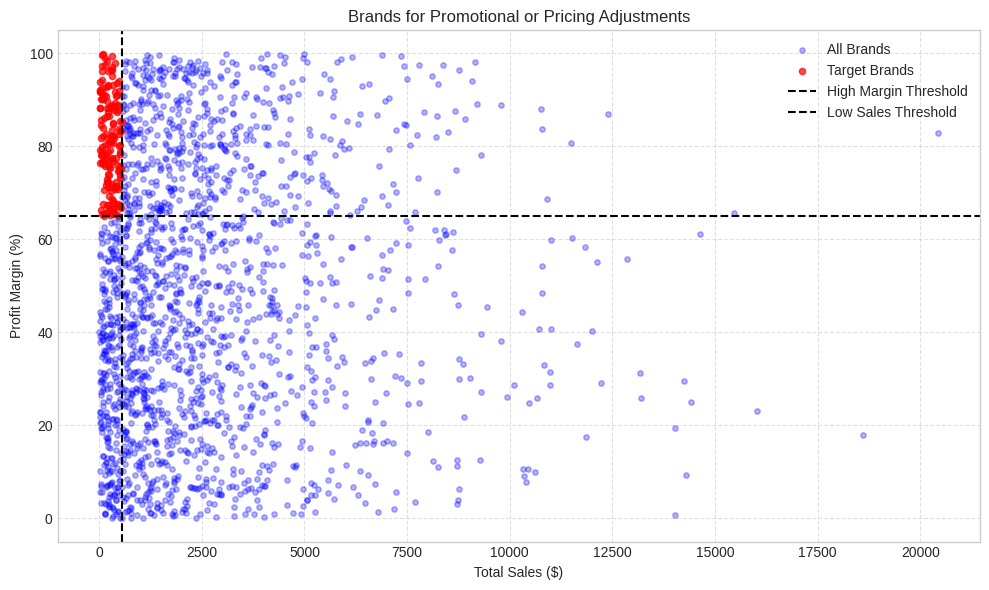

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(42)
sales_all = np.random.exponential(scale=2500, size=2000)
margin_all = np.random.uniform(0, 100, size=2000)

target_filter = (sales_all <= 550) & (margin_all >= 65)

plt.figure(figsize=(10, 6))
plt.scatter(
    sales_all[~target_filter],
    margin_all[~target_filter],
    alpha=0.3,
    color="blue",
    s=15,
    label="All Brands",
)
plt.scatter(
    sales_all[target_filter],
    margin_all[target_filter],
    alpha=0.7,
    color="red",
    s=20,
    label="Target Brands",
)

plt.axhline(
    y=65, color="black", linestyle="--", label="High Margin Threshold"
)
plt.axvline(
    x=550, color="black", linestyle="--", label="Low Sales Threshold"
)

plt.xlabel("Total Sales ($)")
plt.ylabel("Profit Margin (%)")
plt.title("Brands for Promotional or Pricing Adjustments")
plt.legend(loc="upper right")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

Small vs Bulk Orders

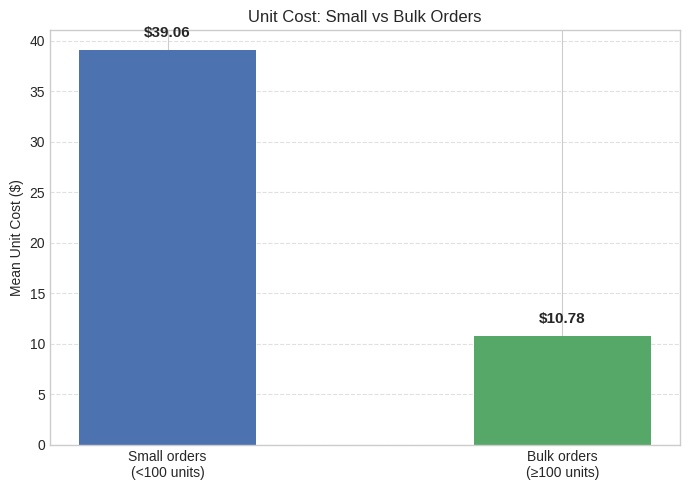

In [ ]:
import matplotlib.pyplot as plt

segments = ["Small orders\n(<100 units)", "Bulk orders\n(≥100 units)"]
unit_costs = [39.06, 10.78]

plt.figure(figsize=(7, 5))
bars = plt.bar(
    segments, unit_costs, color=["#4c72b0", "#55a868"], width=0.45
)

plt.ylabel("Mean Unit Cost ($)")
plt.title("Unit Cost: Small vs Bulk Orders")
plt.grid(axis="y", linestyle="--", alpha=0.6)

for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 1,
        f"${yval:.2f}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

Top vs. Low Vendors

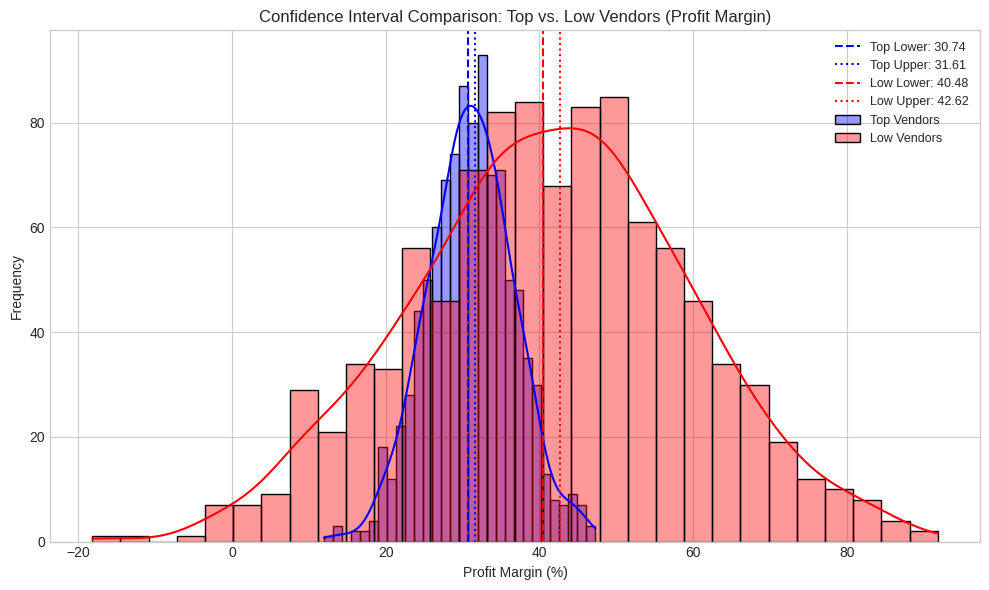

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
np.random.seed(10)

top_vendors_data = np.random.normal(loc=31.17, scale=6, size=1000)
low_vendors_data = np.random.normal(loc=41.55, scale=18, size=1000)

plt.figure(figsize=(10, 6))

sns.histplot(
    top_vendors_data,
    color="blue",
    kde=True,
    alpha=0.4,
    label="Top Vendors",
    bins=30,
)
sns.histplot(
    low_vendors_data,
    color="red",
    kde=True,
    alpha=0.4,
    label="Low Vendors",
    bins=30,
)


plt.axvline(
    30.74, color="blue", linestyle="--", label="Top Lower: 30.74"
)  #[span_5](start_span)[span_5](end_span)[span_6](start_span)[span_6](end_span)
plt.axvline(
    31.61, color="blue", linestyle=":", label="Top Upper: 31.61"
)  #[span_7](start_span)[span_7](end_span)[span_8](start_span)[span_8](end_span)
plt.axvline(
    40.48, color="red", linestyle="--", label="Low Lower: 40.48"
)  #[span_9](start_span)[span_9](end_span)[span_10](start_span)[span_10](end_span)
plt.axvline(
    42.62, color="red", linestyle=":", label="Low Upper: 42.62"
)  #[span_11](start_span)[span_11](end_span)[span_12](start_span)[span_12](end_span)

plt.xlabel("Profit Margin (%)")
plt.ylabel("Frequency")
plt.title(
    "Confidence Interval Comparison: Top vs. Low Vendors (Profit Margin)"
)
plt.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

Statistical Proof: A hypothesis test proves a true difference in profit margins between vendor groups, confirming they operate under distinct models.

​Key Implication: High-margin vendors succeed through better pricing, whereas high-volume sellers need to optimize their cost efficiency.

Final Recommendations:

1) ​Re-evaluate Pricing: Re-evaluate pricing for low-sales, high-margin brands to boost sales volume without sacrificing profitability.  
2) ​Diversify Vendors: Diversify vendor partnerships to reduce dependency on a few suppliers and mitigate supply chain risks.  
3) ​Leverage Bulk Purchasing: Leverage bulk purchasing advantages to maintain competitive pricing while optimizing inventory management.  
4) ​Optimize Slow-Moving Inventory: Optimize slow-moving inventory by adjusting purchase quantities, launching clearance sales, or revising storage strategies.  
5) ​Enhance Marketing & Distribution: Enhance marketing and distribution strategies for low-performing vendors to drive higher sales volumes without compromising profit margins.  
6) ​Achieve Sustainable Growth: By implementing these recommendations, the company can achieve sustainable profitability, mitigate risks, and enhance overall operational efficiency.